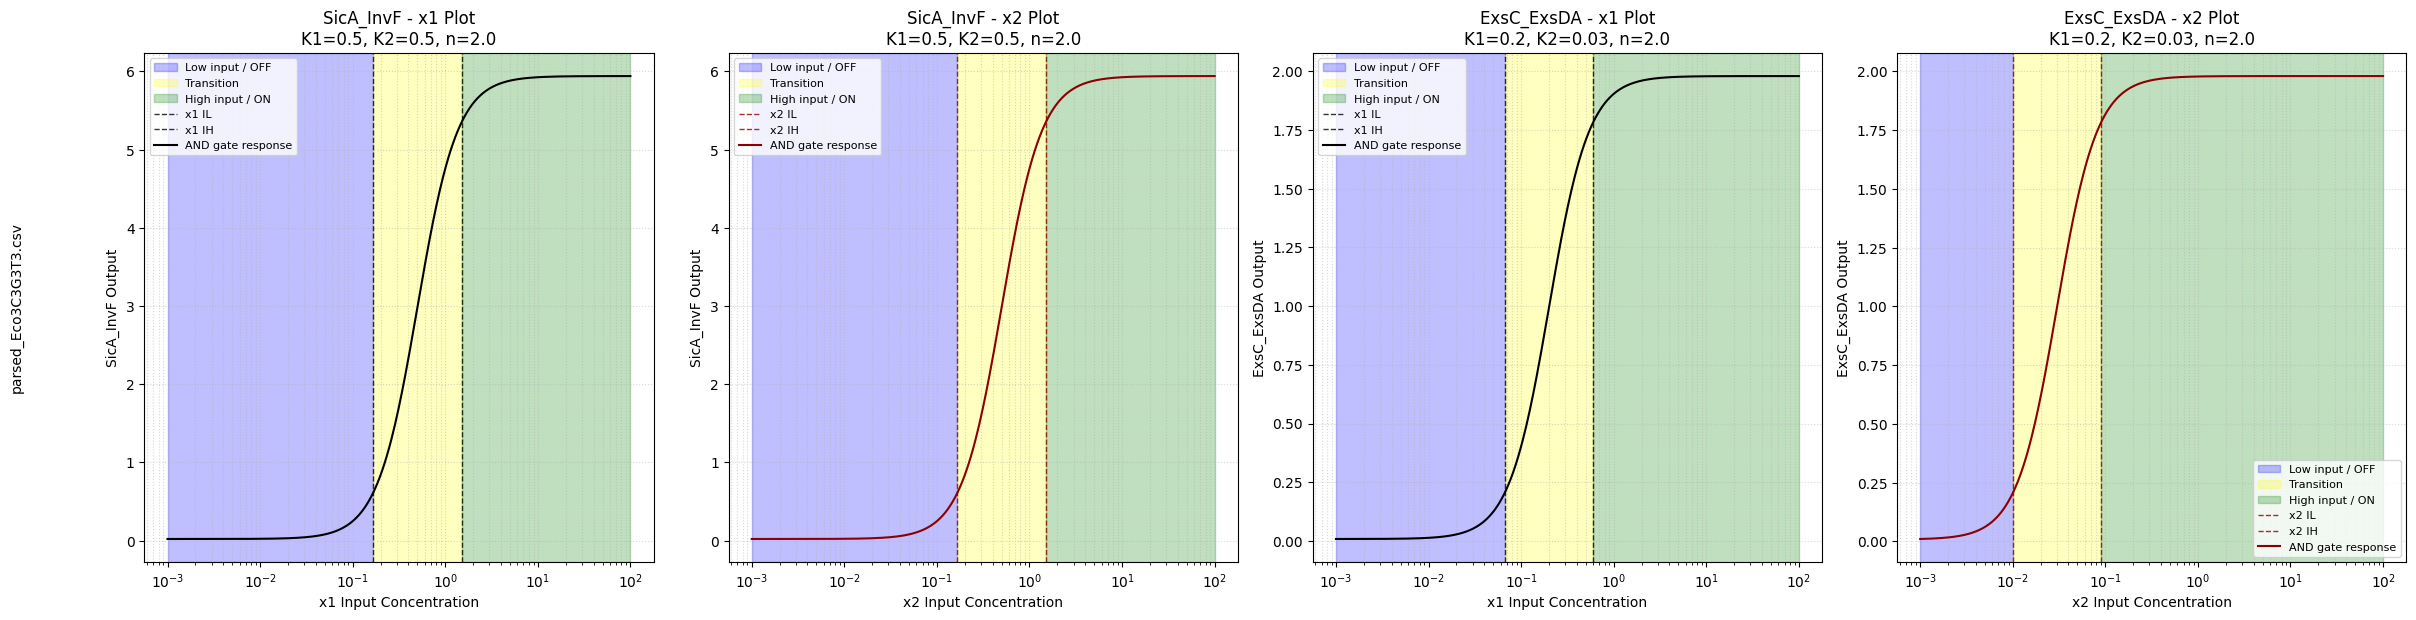

Saved AND thresholds to /home/shrut/bioCircuitProject/library/AND_gate/and_thresholds.csv


In [1]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

# for the AND graphs
    # ON is defined by: (x1 > IH1 AND x2 > IH2)
    # OFF is defined by: (x1 < IL1 OR x2 < IL2)
    # transition is defined by: (IL < x < IH) for the inputs
    # the AND csv has no IL/IH, so we compute them from the SLOPE of the curve:
    #   IL = x where the slope rises through 1 (flat OFF zone -> steep transition zone)
    #   IH = x where the slope falls back through 1 (steep transition zone -> flat ON zone)
    # if both x1 and x2 -> 0, the output is (ymin) low
    # if both x1 and x2 -> infinity, the output is (ymax) high
# the AND gate equation: ymin + (ymax-ymin) * (x1^n / (K1^n + x1^n)) * (x2^n / (K2^n + x2^n))
#if slope is linear: transition region 

csv_files = ["parsed_Eco3C3G3T3.csv"]
FIXED_MULT = 10
threshold_values = {}
threshold_rows = []

def hill(x, K, n):
    return x**n / (K**n + x**n)


def and_gate(x1, x2, row):
    return row["ymin"] + (row["ymax"] - row["ymin"]) * hill(
        x1, row["K1"], row["n"]
    ) * hill(x2, row["K2"], row["n"])


def response_thresholds(K, n):
  
    il = K * (0.1 / 0.9)**(1 / n)
    ih = K * (0.9 / 0.1)**(1 / n)

    return il, ih


files = []

for csv_path in csv_files:
    data = pd.read_csv(csv_path)

    required_columns = {
        "name", "type", "ymax", "ymin", "K1", "K2", "n"
    }

    missing_columns = required_columns.difference(data.columns)

    if missing_columns:
        raise ValueError(
            f"{csv_path} is missing columns: {sorted(missing_columns)}"
        )

    and_rows = data.loc[data["type"].eq("AND")].reset_index(drop=True)

    if and_rows.empty:
        raise ValueError(f"{csv_path} contains no AND gates to plot.")

    files.append((csv_path, and_rows))


n_columns = max(2 * len(and_rows) for _, and_rows in files)

fig, axes = plt.subplots(
    len(files),
    n_columns,
    figsize=(6 * n_columns, 6 * len(files)),
    squeeze=False,
)


for file_index, (csv_path, and_rows) in enumerate(files):

    for gate_index, (_, gate) in enumerate(and_rows.iterrows()):

        ymin = float(gate["ymin"])
        ymax = float(gate["ymax"])
        k1 = float(gate["K1"])
        k2 = float(gate["K2"])
        n = float(gate["n"])

        output_name = str(gate["name"])


        x2_fixed = FIXED_MULT * k2
        x1_fixed = FIXED_MULT * k1

        il1, ih1 = response_thresholds(k1, n)
        il2, ih2 = response_thresholds(k2, n)
        file_key = Path(csv_path).stem
        threshold_values.setdefault(file_key, {})[output_name] = {
            "x1": {"IL": il1, "IH": ih1},
            "x2": {"IL": il2, "IH": ih2},
        }
        threshold_rows.append({
            "source_file": Path(csv_path).name,
            "gate": output_name,
            "IL1": il1,
            "IH1": ih1,
            "IL2": il2,
            "IH2": ih2,
        })

        # Each gate occupies two adjacent columns.
        x1_axis = axes[file_index, 2 * gate_index]
        x2_axis = axes[file_index, 2 * gate_index + 1]


        transition_min1 = il1
        transition_max1 = ih1

        x_min1 = min(1e-3, transition_min1 / 10)
        x_max1 = max(1e2, transition_max1 * 10)

        x1 = np.logspace(
            np.log10(x_min1),
            np.log10(x_max1),
            400
        )

        #shading
        x1_axis.axvspan(
            x_min1, transition_min1,
            color="blue",
            alpha=0.25,
            label="Low input / OFF"
        )

        x1_axis.axvspan(
            transition_min1, transition_max1,
            color="yellow",
            alpha=0.25,
            label="Transition"
        )

        x1_axis.axvspan(
            transition_max1, x_max1,
            color="green",
            alpha=0.25,
            label="High input / ON"
        )

  
        for threshold_name, value in (("IL", il1), ("IH", ih1)):
            x1_axis.axvline(
                value,
                color="black",
                linestyle="--",
                linewidth=1.0,
                alpha=0.8,
                label=f"x1 {threshold_name}"
            )

        x1_axis.plot(
            x1,
            and_gate(x1, x2_fixed, gate),
            color="black",
            linewidth=1.5,
            label="AND gate response",
            zorder=2
        )

        x1_axis.set_xscale("log")
        x1_axis.set_box_aspect(1)

        x1_axis.set_title(
            f"{output_name} - x1 Plot\n"
            f"K1={k1}, K2={k2}, n={n}"
        )

        x1_axis.set_xlabel("x1 Input Concentration")
        x1_axis.set_ylabel(f"{output_name} Output")

        x1_axis.grid(
            True,
            which="both",
            linestyle=":",
            alpha=0.5
        )

        x1_axis.legend(loc="best", fontsize=8)

        transition_min2 = il2
        transition_max2 = ih2

        x_min2 = min(1e-3, transition_min2 / 10)
        x_max2 = max(1e2, transition_max2 * 10)

        x2 = np.logspace(
            np.log10(x_min2),
            np.log10(x_max2),
            400
        )

        x2_axis.axvspan(
            x_min2, transition_min2,
            color="blue",
            alpha=0.25,
            label="Low input / OFF"
        )

        x2_axis.axvspan(
            transition_min2, transition_max2,
            color="yellow",
            alpha=0.25,
            label="Transition"
        )

        x2_axis.axvspan(
            transition_max2, x_max2,
            color="green",
            alpha=0.25,
            label="High input / ON"
        )

       
        for threshold_name, value in (("IL", il2), ("IH", ih2)):
            x2_axis.axvline(
                value,
                color="darkred",
                linestyle="--",
                linewidth=1.0,
                alpha=0.8,
                label=f"x2 {threshold_name}"
            )

    
        x2_axis.plot(
            x2,
            and_gate(x1_fixed, x2, gate),
            color="darkred",
            linewidth=1.5,
            label="AND gate response",
            zorder=2
        )

        x2_axis.set_xscale("log")
        x2_axis.set_box_aspect(1)

        x2_axis.set_title(
            f"{output_name} - x2 Plot\n"
            f"K1={k1}, K2={k2}, n={n}"
        )

        x2_axis.set_xlabel("x2 Input Concentration")
        x2_axis.set_ylabel(f"{output_name} Output")

        x2_axis.grid(
            True,
            which="both",
            linestyle=":",
            alpha=0.5
        )

        x2_axis.legend(loc="best", fontsize=8)


    # Hide unused columns if CSV files have different numbers of AND gates.
    for unused_column in range(2 * len(and_rows), n_columns):
        axes[file_index, unused_column].set_visible(False)

    # Label each CSV row.
    axes[file_index, 0].annotate(
        Path(csv_path).name,
        xy=(-0.25, 0.5),
        xycoords="axes fraction",
        rotation=90,
        ha="center",
        va="center"
    )


plt.tight_layout()
plt.show()

threshold_output = Path(csv_files[0]).parent / "and_thresholds.csv"
pd.DataFrame(threshold_rows).to_csv(threshold_output, index=False)
print(f"Saved AND thresholds to {threshold_output.resolve()}")
